# ARGus + DNABERT-2 (CPU) · embeddings congelados + cabeza en PyTorch

**Qué hace:** DNABERT-2 (preentrenado, congelado) convierte cada fragmento de 500 pb en un vector de 768 números.
Sobre esos vectores se entrena una cabeza pequeña en PyTorch con **tres conjuntos (train / val / test)** y un **checkpoint del mejor `val_loss`**
(como en el ejemplo de la asesora, pero en PyTorch).

**Mismo protocolo que ARGus v2 (RF k=6), para que la comparación sea directa:**
- Mismo test por gen (misma semilla), mismos 2000 genes del 1k+1k fuera del entrenamiento.
- Random Undersampling solo de negativos, 1:1, solo en train y val; el test queda con su proporción natural.
- La partición es **por gen** (no `train_test_split` simple): un gen tiene varios fragmentos y con la partición simple quedarían fragmentos del mismo gen en train y test.

**Antes de correr:** ambiente `dnabert` (ver instrucciones en el chat). Los embeddings se guardan en disco por bloques: puedes detener y reanudar.
**Primero deja `PRUEBA_RAPIDA = True`** (celda 1) para validar todo en pocos minutos; luego ponlo en `False`.

In [ ]:
# ============ CELDA 1: configuración ============
import re, time, json, os, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix)

PRUEBA_RAPIDA = False      # True = submuestra pequeña para validar el pipeline (minutos). False = corrida completa.
RESUME = True             # reanuda la cabeza desde el último checkpoint si existe

INTERIM_MANUAL = "/mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/interim"
INTERIM = Path(INTERIM_MANUAL)
if not (INTERIM / "dataset_fragmentado_500.tsv").exists():
    hits = []
    for raiz in (Path("/mnt/c/Users"), Path.home()):
        if raiz.exists(): hits += list(raiz.rglob("dataset_fragmentado_500.tsv"))
    assert hits, "No encontré dataset_fragmentado_500.tsv: corrige INTERIM_MANUAL"
    INTERIM = hits[0].parent
print("INTERIM =", INTERIM)

DATASET_FRAG = INTERIM / "dataset_fragmentado_500.tsv"
SET_1K1K     = INTERIM / "muestra_genes_labels.tsv"
FASTA_1K1K   = INTERIM / "muestra_genes_completos.fasta"
SALIDA = INTERIM.parent / "models"; SALIDA.mkdir(parents=True, exist_ok=True)

ETIQUETA_CORRIDA = "id95"
SEED = 42
FRAC_TEST = 0.10          # 10 % de los genes para test (mismo pliegue que el RF)
N_FOLDS_VAL = 9           # de lo que queda (90 %), 1/9 -> 10 % del total para validación
MODELO_HF = "zhihan1996/DNABERT-2-117M"
BATCH = 16                # fragmentos por lote al codificar
CHUNK = 512               # fragmentos por bloque guardado en disco
EPOCHS = 60; PACIENCIA = 6; LR = 1e-3; BATCH_CABEZA = 128

torch.set_num_threads(os.cpu_count())
print("hilos CPU:", torch.get_num_threads(), "| torch", torch.__version__, "| numpy", np.__version__)

INTERIM = /mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/interim
hilos CPU: 12 | torch 2.14.1+cpu | numpy 1.26.4


In [2]:
# ============ CELDA 2: datos, gen por fragmento, exclusión del 1k+1k (igual que el RF) ============
frag = pd.read_csv(DATASET_FRAG, sep="\t")
col_id, col_seq, col_lab = "id", "lectura", "etiqueta"
assert {col_id, col_seq, col_lab} <= set(frag.columns), f"columnas: {list(frag.columns)}"
frag[col_lab] = frag[col_lab].astype(int)
frag["gen"] = frag[col_id].str.replace(r"__frag\d+$", "", regex=True)

lab1k = pd.read_csv(SET_1K1K, sep="\t")
ids_1k = set(lab1k.iloc[:, 0].astype(str))
genes_frag = set(frag["gen"])
excluir = ids_1k & genes_frag
faltan = ids_1k - excluir
if faltan:
    variantes = {}
    for g in genes_frag: variantes.setdefault(g.split("|", 1)[-1], g)
    for f in list(faltan):
        if f in variantes: excluir.add(variantes[f]); faltan.discard(f)
assert not faltan, f"No encontré genes del 1k+1k: {list(faltan)[:5]}"
print("genes del 1k+1k excluidos:", len(excluir), "de", len(ids_1k))

pool = frag[~frag["gen"].isin(excluir)].reset_index(drop=True)
print(pool[col_lab].value_counts().rename({0: "neg (frag)", 1: "pos (frag)"}))

genes del 1k+1k excluidos: 2000 de 2000
etiqueta
neg (frag)    60978
pos (frag)     7229
Name: count, dtype: int64


In [3]:
# ============ CELDA 3: tres conjuntos por gen (train / val / test) + undersampling de negativos ============
y_all = pool[col_lab].values; g_all = pool["gen"].values
seqs_all = pool[col_seq].astype(str).values

# 1) test: mismo pliegue que el RF (misma semilla y mismo pool) -> comparación directa
sgkf = StratifiedGroupKFold(n_splits=int(round(1 / FRAC_TEST)), shuffle=True, random_state=SEED)
tr_full, te = next(sgkf.split(np.zeros(len(y_all)), y_all, g_all))
# 2) val: 1/9 de lo que queda, también separado por gen
sgkf2 = StratifiedGroupKFold(n_splits=N_FOLDS_VAL, shuffle=True, random_state=SEED)
tr_i, va_i = next(sgkf2.split(np.zeros(len(tr_full)), y_all[tr_full], g_all[tr_full]))
tr, va = tr_full[tr_i], tr_full[va_i]
assert not (set(g_all[tr]) & set(g_all[va])) and not (set(g_all[tr]) & set(g_all[te])) and not (set(g_all[va]) & set(g_all[te])), "FUGA entre conjuntos"

rng = np.random.default_rng(SEED)
def submuestrear(idx):                      # todos los positivos + igual número de negativos al azar
    p = idx[y_all[idx] == 1]; n = idx[y_all[idx] == 0]
    sel = np.concatenate([p, rng.choice(n, size=min(len(p), len(n)), replace=False)]); rng.shuffle(sel)
    return sel
tr_b, va_b = submuestrear(tr), submuestrear(va)
te_n = te                                    # test: distribución natural

if PRUEBA_RAPIDA:                            # submuestra pequeña solo para validar el pipeline
    tr_b, va_b = tr_b[:300], va_b[:100]
    te_n = rng.choice(te, size=min(300, len(te)), replace=False)

for nombre, idx in [("train (balanceado)", tr_b), ("val (balanceado)", va_b), ("test (natural)", te_n)]:
    print(f"{nombre:20s}: {len(idx):6,}  pos={int((y_all[idx]==1).sum()):,}  neg={int((y_all[idx]==0).sum()):,}")

# fragmentos de los 1k+1k (genes completos, sin ver en entrenamiento)
def leer_fasta(path):
    d, cur = {}, None
    for l in open(path):
        l = l.strip()
        if l.startswith(">"): cur = l[1:].split()[0]; d[cur] = []
        elif cur: d[cur].append(l)
    return {k: "".join(v) for k, v in d.items()}
def fragmentar(seq, ventana=500):
    seq = seq.upper(); L = len(seq)
    if L < ventana: return [seq + "0" * (ventana - L)]
    n = L // ventana; fr = [seq[i*ventana:(i+1)*ventana] for i in range(n)]
    r = L - n * ventana
    if r > 0: fr.append(seq[n*ventana:] + "0" * (ventana - r))
    return fr

fa = leer_fasta(FASTA_1K1K)
y_1k = dict(zip(lab1k.iloc[:, 0].astype(str), lab1k.iloc[:, 1].astype(int)))
ids_g = [i for i in fa if i in y_1k]
if PRUEBA_RAPIDA: ids_g = ids_g[:100] + [i for i in ids_g if y_1k[i] == 1][:100]
seqs_1k, gen_1k = [], []
for gid in ids_g:
    fr = fragmentar(fa[gid]); seqs_1k += fr; gen_1k += [gid] * len(fr)
gen_1k = np.array(gen_1k)
print(f"1k+1k: {len(ids_g)} genes -> {len(seqs_1k):,} fragmentos")

train (balanceado)  :    300  pos=152  neg=148
val (balanceado)    :    100  pos=52  neg=48
test (natural)      :    300  pos=32  neg=268
1k+1k: 200 genes -> 452 fragmentos


In [4]:
# ============ CELDA 4: cargar DNABERT-2 y medir velocidad (cuánto va a tardar) ============
from transformers import AutoTokenizer, AutoModel, AutoConfig
# --- carga del modelo ---
tokenizer = AutoTokenizer.from_pretrained(MODELO_HF, trust_remote_code=True)
try:
    model = AutoModel.from_pretrained(MODELO_HF, trust_remote_code=True)
except Exception as e:                       # transformers nuevos: el README indica cargar la config primero
    print("carga directa falló (", type(e).__name__, "): reintento con la config")
    cfg = AutoConfig.from_pretrained(MODELO_HF, trust_remote_code=True)
    model = AutoModel.from_pretrained(MODELO_HF, config=cfg, trust_remote_code=True)
model.eval()

def codificar(seqs):
    # quita el relleno de ceros (el modelo recibe solo nucleótidos reales); promedio de tokens con máscara
    seqs = [(s.rstrip("0") or "A") for s in seqs]
    out = []
    for i in range(0, len(seqs), BATCH):
        enc = tokenizer(seqs[i:i+BATCH], return_tensors="pt", padding=True)
        with torch.inference_mode():
            h = model(enc["input_ids"], attention_mask=enc["attention_mask"])[0]
        m = enc["attention_mask"].unsqueeze(-1).float()
        out.append(((h * m).sum(1) / m.sum(1)).numpy())
    return np.concatenate(out)
# --- fin carga ---

print("parámetros del modelo:", f"{sum(p.numel() for p in model.parameters())/1e6:.0f} M")
codificar(seqs_all[tr_b[:BATCH]])                       # calentamiento
t0 = time.time(); e = codificar(seqs_all[tr_b[:48]]); dt = (time.time() - t0) / 48
print("embedding:", e.shape, f"| {dt:.2f} s por fragmento")
total = len(tr_b) + len(va_b) + len(te_n) + len(seqs_1k)
print(f"fragmentos a codificar: {total:,}  ->  tiempo estimado: {total*dt/3600:.1f} h  ({total*dt/60:.0f} min)")

/home/r4gbi/miniconda3/envs/dnabert/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/r4gbi/miniconda3/envs/dnabert/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- configuration_bert.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
A new version of the following files was downloaded from https://huggingface.co/zhihan1996/DNABERT-2-117M:
- flash_attn_triton.py
. Make sure

parámetros del modelo: 117 M
embedding: (48, 768) | 0.06 s por fragmento
fragmentos a codificar: 1,152  ->  tiempo estimado: 0.0 h  (1 min)


In [5]:
# ============ CELDA 5: codificar todo (por bloques en disco; se puede interrumpir y reanudar) ============
def firma(seqs):
    h = hashlib.md5(); [h.update(s.encode()) for s in seqs]; return h.hexdigest()[:10]

def embeddings(seqs, nombre):
    seqs = list(seqs); d = SALIDA / "dnabert2_emb" / f"{nombre}_{len(seqs)}_{firma(seqs)}"; d.mkdir(parents=True, exist_ok=True)
    bloques, t0 = [], time.time()
    for b, i in enumerate(range(0, len(seqs), CHUNK)):
        f = d / f"{b:05d}.npy"
        if not f.exists(): np.save(f, codificar(seqs[i:i+CHUNK]))
        bloques.append(np.load(f))
        hechos = min(i + CHUNK, len(seqs))
        print(f"\r{nombre}: {hechos:,}/{len(seqs):,}  ({(time.time()-t0)/60:.1f} min)", end="")
    print(); return np.concatenate(bloques)

E_tr = embeddings(seqs_all[tr_b], "train"); y_tr = y_all[tr_b]
E_va = embeddings(seqs_all[va_b], "val");   y_va = y_all[va_b]
E_te = embeddings(seqs_all[te_n], "test");  y_te = y_all[te_n]; g_te = g_all[te_n]
E_1k = embeddings(seqs_1k, "1k1k")
print("listo:", E_tr.shape, E_va.shape, E_te.shape, E_1k.shape)

train: 300/300  (0.3 min)
val: 100/100  (0.1 min)
test: 300/300  (0.3 min)
1k1k: 452/452  (0.5 min)
listo: (300, 768) (100, 768) (300, 768) (452, 768)


In [6]:
# ============ CELDA 6: cabeza en PyTorch con checkpoint del mejor val_loss ============
torch.manual_seed(SEED)
mu, sd = E_tr.mean(0), E_tr.std(0) + 1e-6                       # estandarizar con estadísticas del train
T = lambda a: torch.tensor((a - mu) / sd, dtype=torch.float32)
Xtr, Xva = T(E_tr), T(E_va)
ytr, yva = torch.tensor(y_tr, dtype=torch.float32), torch.tensor(y_va, dtype=torch.float32)

D = E_tr.shape[1]
head = nn.Sequential(nn.Linear(D, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 1))
opt = torch.optim.Adam(head.parameters(), lr=LR, weight_decay=1e-4)
loss_fn = nn.BCEWithLogitsLoss()        # sin class_weight: train y val ya están balanceados 1:1 por el undersampling

CK_BEST = SALIDA / f"dnabert2_head_best_{ETIQUETA_CORRIDA}.pt"
CK_LAST = SALIDA / f"dnabert2_head_last_{ETIQUETA_CORRIDA}.pt"
initial_epoch, best, sin_mejora = 0, float("inf"), 0
if RESUME and CK_LAST.exists():
    ck = torch.load(CK_LAST); head.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
    initial_epoch, best, sin_mejora = ck["epoch"], ck["best"], ck["sin_mejora"]
    print(f"reanudando desde la época {initial_epoch} (mejor val_loss {best:.4f})")

for ep in range(initial_epoch, EPOCHS):
    head.train(); perm = torch.randperm(len(Xtr)); tl = 0
    for i in range(0, len(Xtr), BATCH_CABEZA):
        b = perm[i:i+BATCH_CABEZA]
        opt.zero_grad(); l = loss_fn(head(Xtr[b]).squeeze(1), ytr[b]); l.backward(); opt.step(); tl += l.item() * len(b)
    head.eval()
    with torch.no_grad(): vl = loss_fn(head(Xva).squeeze(1), yva).item()
    mejora = vl < best
    if mejora: best, sin_mejora = vl, 0; torch.save(head.state_dict(), CK_BEST)     # save_best_only (monitor = val_loss)
    else: sin_mejora += 1
    torch.save({"model": head.state_dict(), "opt": opt.state_dict(), "epoch": ep + 1, "best": best, "sin_mejora": sin_mejora}, CK_LAST)
    print(f"época {ep+1:3d}  train_loss {tl/len(Xtr):.4f}  val_loss {vl:.4f} {'*' if mejora else ''}")
    if sin_mejora >= PACIENCIA: print("early stopping"); break

head.load_state_dict(torch.load(CK_BEST)); head.eval()
print("mejor val_loss:", round(best, 4), "->", CK_BEST.name)

época   1  train_loss 0.6805  val_loss 0.6412 *
época   2  train_loss 0.5547  val_loss 0.6382 *
época   3  train_loss 0.4742  val_loss 0.6290 *
época   4  train_loss 0.4236  val_loss 0.6355 
época   5  train_loss 0.3954  val_loss 0.6174 *
época   6  train_loss 0.3458  val_loss 0.6012 *
época   7  train_loss 0.3173  val_loss 0.6023 
época   8  train_loss 0.2846  val_loss 0.6047 
época   9  train_loss 0.2608  val_loss 0.6073 
época  10  train_loss 0.2338  val_loss 0.6164 
época  11  train_loss 0.2024  val_loss 0.6208 
época  12  train_loss 0.1835  val_loss 0.6208 
early stopping
mejor val_loss: 0.6012 -> dnabert2_head_best_id95.pt


In [7]:
# ============ CELDA 7: evaluación (test natural y 1k+1k) y comparación ============
def prob(E):
    with torch.no_grad(): return torch.sigmoid(head(T(E)).squeeze(1)).numpy()
def metricas(y, pred, p=None):
    d = dict(recall=recall_score(y, pred), precision=precision_score(y, pred, zero_division=0), f1=f1_score(y, pred))
    if p is not None: d["auc"] = roc_auc_score(y, p)
    return d

p_te = prob(E_te); pred_te = (p_te >= 0.5).astype(int)
print("== TEST, FRAGMENTO ==", {k: round(v, 3) for k, v in metricas(y_te, pred_te, p_te).items()})
print(confusion_matrix(y_te, pred_te))
gg = pd.DataFrame({"gen": g_te, "y": y_te, "p": p_te}).groupby("gen").agg(y=("y", "max"), p=("p", "max"))
print("== TEST, GEN (any) ==", {k: round(v, 3) for k, v in metricas(gg.y, (gg.p >= 0.5).astype(int), gg.p).items()}, "| genes:", len(gg))

# 1k+1k: un gen es ARG si algún fragmento lo es (misma regla que ARGus)
p1 = prob(E_1k)
r1k = pd.DataFrame({"gen": gen_1k, "p": p1}).groupby("gen")["p"].max().reset_index()
r1k["y"] = r1k["gen"].map(y_1k); r1k["pred"] = (r1k["p"] >= 0.5).astype(int)
m_dn = metricas(r1k.y, r1k.pred, r1k.p)
print("== 1k+1k, GEN ==", {k: round(v, 3) for k, v in m_dn.items()})
print(confusion_matrix(r1k.y, r1k.pred))
if PRUEBA_RAPIDA: print("\n(PRUEBA_RAPIDA = True: estos números son solo para validar el pipeline; no los uses)")

csv = SALIDA / f"comparacion_{ETIQUETA_CORRIDA}.csv"           # la deja el cuaderno argus_k6_id95
if csv.exists():
    res = pd.read_csv(csv, index_col=0)
    res.loc["DNABERT-2 (emb + MLP)"] = [round(m_dn["recall"], 3), round(m_dn["precision"], 3), round(m_dn["f1"], 3)]
else:
    print("No encontré", csv.name, "(corre antes argus_k6_id95.ipynb para tener las otras filas)")
    res = pd.DataFrame({"DNABERT-2 (emb + MLP)": {k: round(m_dn[k], 3) for k in ("recall", "precision", "f1")}}).T
print(res)
if not PRUEBA_RAPIDA: res.to_csv(SALIDA / f"comparacion_dnabert2_{ETIQUETA_CORRIDA}.csv")

== TEST, FRAGMENTO == {'recall': 0.656, 'precision': 0.186, 'f1': 0.29, 'auc': 0.712}
[[176  92]
 [ 11  21]]
== TEST, GEN (any) == {'recall': 0.656, 'precision': 0.188, 'f1': 0.292, 'auc': 0.705} | genes: 289
== 1k+1k, GEN == {'recall': 0.81, 'precision': 1.0, 'f1': 0.895, 'auc': nan}
[[ 0  0]
 [19 81]]

(PRUEBA_RAPIDA = True: estos números son solo para validar el pipeline; no los uses)
                               recall  precision     f1
ARGus v1 (k=4)                  0.893      0.745  0.813
ARGus v2 (k=6, undersampling)   0.893      0.752  0.817
ARGNet (argnet-s, OR)           0.589      0.882  0.706
DeepARG (id30)                  0.720      0.978  0.829
DNABERT-2 (emb + MLP)           0.810      1.000  0.895


/home/r4gbi/miniconda3/envs/dnabert/lib/python3.10/site-packages/sklearn/metrics/_ranking.py:424: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


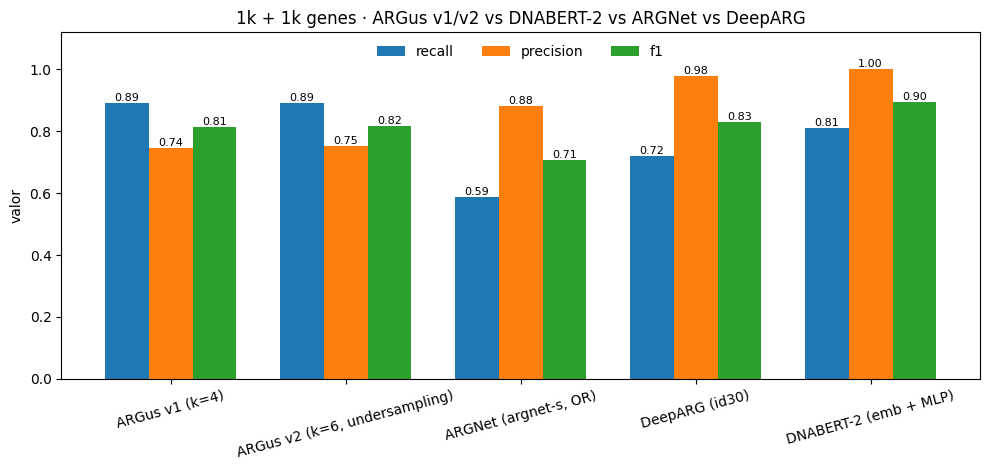

In [8]:
# ============ CELDA 8: gráfica ============
import matplotlib.pyplot as plt
ax = res.plot.bar(figsize=(10, 4.8), rot=15, width=0.75)
ax.set_ylim(0, 1.12); ax.set_ylabel("valor"); ax.set_title("1k + 1k genes · ARGus v1/v2 vs DNABERT-2 vs ARGNet vs DeepARG")
ax.legend(loc="upper center", ncol=3, frameon=False)
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout()
if not PRUEBA_RAPIDA: plt.savefig(SALIDA / f"comparacion_dnabert2_{ETIQUETA_CORRIDA}.png", dpi=200)
plt.show()